In [8]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn (1).csv')

# 2. Display dataset shape (Rows, Columns)
print("\n=== Dataset Shape ===")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 3. Display column names and data types
print("\n=== Column Names and Data Types ===")
print(df.dtypes)

# 4. Display basic summary statistics for numerical features
print("\n=== Basic Statistics (Numerical Features) ===")
print(df.describe())

# 5. Display basic summary statistics for categorical features
print("\n=== Basic Statistics (Categorical Features) ===")
print(df.describe(include=['object']))

# 6. Identify target variable distribution (Churn)
print("\n=== Target Variable (Churn) Count ===")
print(df['Churn'].value_counts())

print("\n=== Target Variable Percentage ===")
print(df['Churn'].value_counts(normalize=True) * 100)


=== Dataset Shape ===
Rows: 7043
Columns: 21

=== Column Names and Data Types ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== Basic Statistics (Numerical Features) ===
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.0000

In [12]:
import numpy as np

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# 3. Fix incorrect data type for TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(" ", np.nan), errors="coerce"
)

# 4. Fill missing values in TotalCharges with median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# 5. Remove duplicate records
df = df.drop_duplicates()

# 6. Remove unnecessary column
df_clean = df.drop(columns=["customerID"])

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate records: 0


/tmp/ipykernel_1291/3065203384.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="Churn", palette="Blues_d")


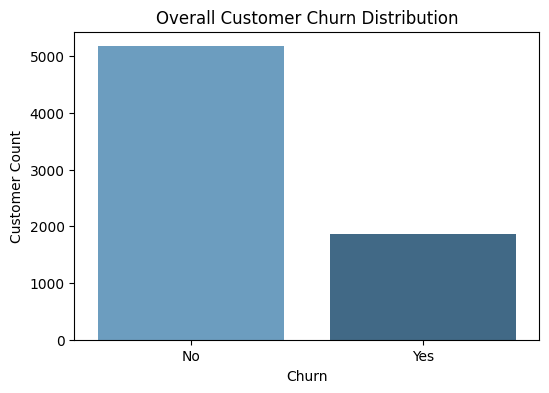

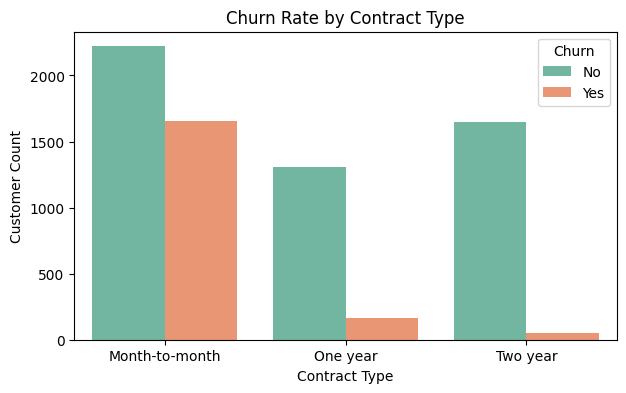

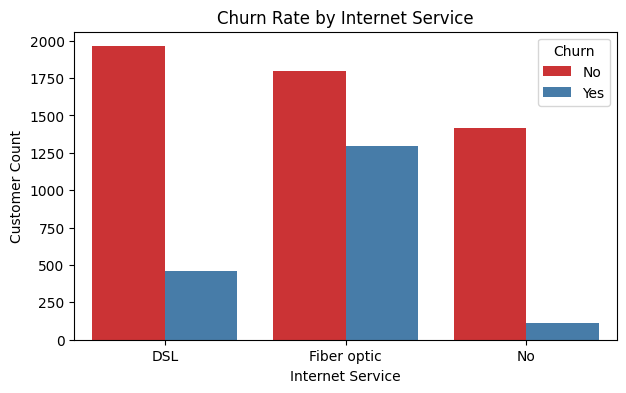

/tmp/ipykernel_1291/3065203384.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Churn", y="tenure", palette="Pastel1")


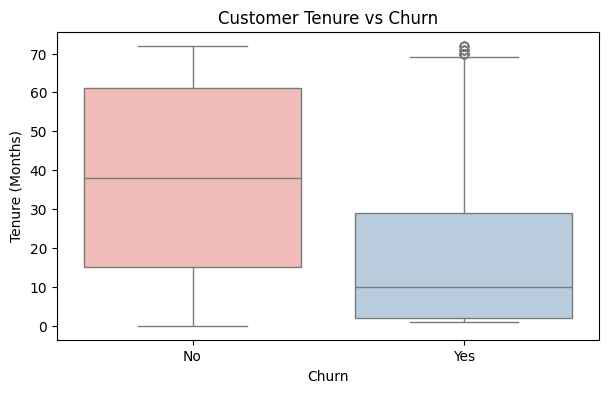

=== Table 1: Churn Distribution ===
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

=== Table 2: Churn by Contract Type ===
Churn             No   Yes   All
Contract                        
Month-to-month  2220  1655  3875
One year        1307   166  1473
Two year        1647    48  1695
All             5174  1869  7043

=== Table 3: Average Metrics by Churn Status ===
          tenure  MonthlyCharges  TotalCharges
Churn                                         
No     37.569965       61.265124   2552.882494
Yes    17.979133       74.441332   1531.796094


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Churn Distribution Plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="Churn", palette="Blues_d")
plt.title("Overall Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Customer Count")
plt.show()

# 2. Relationship between Contract Type and Churn
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="Contract", hue="Churn", palette="Set2")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")
plt.show()

# 3. Relationship between Internet Service and Churn
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="InternetService", hue="Churn", palette="Set1")
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Customer Count")
plt.show()

# 4. Relationship between Customer Tenure and Churn
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x="Churn", y="tenure", palette="Pastel1")
plt.title("Customer Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

# Summary Tables
print("=== Table 1: Churn Distribution ===")
print(df_clean["Churn"].value_counts(normalize=True) * 100)

print("\n=== Table 2: Churn by Contract Type ===")
print(pd.crosstab(df_clean["Contract"], df_clean["Churn"], margins=True))

print("\n=== Table 3: Average Metrics by Churn Status ===")
print(
    df_clean.groupby("Churn")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean()
)


In [15]:
import pandas as pd

# 1. Separate target variable y from input features X
X = df_clean.drop(columns=["Churn"])
y = df_clean["Churn"].map({"Yes": 1, "No": 0})

# 2. Identify categorical columns that need encoding
categorical_cols = X.select_dtypes(include=["object"]).columns

# 3. Convert categorical variables to numerical using One-Hot Encoding
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# 4. Verify shapes of X and y
print("\nShape of X (features):", X_encoded.shape)
print("Shape of y (target):", y.shape)


Shape of X (features): (7043, 30)
Shape of y (target): (7043,)


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Split dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# 2. Scale features for distance-sensitive models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
print("Logistic Regression trained successfully.")

# 4. Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Random Forest Classifier trained successfully.")

Training set shape: (5634, 30)
Testing set shape: (1409, 30)
Logistic Regression trained successfully.
Random Forest Classifier trained successfully.


In [17]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Function to calculate and print evaluation metrics
def evaluate_model(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)

    print(f"=== {model_name} Evaluation Metrics ===")
    print(f"Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
    print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
    print(f"Recall:    {rec:.4f} ({rec*100:.2f}%)")
    print(f"F1-Score:  {f1:.4f} ({f1*100:.2f}%)")
    print("\nConfusion Matrix:")
    print(cm)
    print("-" * 40)


# 1. Evaluate Logistic Regression
y_pred_lr = lr_model.predict(X_test_scaled)
evaluate_model("Logistic Regression", y_test, y_pred_lr)

# 2. Evaluate Random Forest Classifier
y_pred_rf = rf_model.predict(X_test)
evaluate_model("Random Forest Classifier", y_test, y_pred_rf)

=== Logistic Regression Evaluation Metrics ===
Accuracy:  0.8070 (80.70%)
Precision: 0.6584 (65.84%)
Recall:    0.5668 (56.68%)
F1-Score:  0.6092 (60.92%)

Confusion Matrix:
[[925 110]
 [162 212]]
----------------------------------------
=== Random Forest Classifier Evaluation Metrics ===
Accuracy:  0.7864 (78.64%)
Precision: 0.6237 (62.37%)
Recall:    0.4920 (49.20%)
F1-Score:  0.5501 (55.01%)

Confusion Matrix:
[[924 111]
 [190 184]]
----------------------------------------


In [18]:
# Select the best model (Logistic Regression) from Task 6
final_model = lr_model

# Sample Customer 1: Long-term customer
customer_1 = X_test.iloc[[0]]
customer_1_scaled = scaler.transform(customer_1)

pred_1 = final_model.predict(customer_1_scaled)[0]
prob_1 = final_model.predict_proba(customer_1_scaled)[0][1]

print("=== Sample Customer 1 Prediction ===")
print(
    f"Prediction Output: {pred_1} -> {'Yes (Churn)' if pred_1 == 1 else 'No (No Churn)'}"
)
print(f"Churn Probability: {prob_1:.2%}")

# Sample Customer 2: High-risk customer
customer_2 = X_test.iloc[[1]]
customer_2_scaled = scaler.transform(customer_2)

pred_2 = final_model.predict(customer_2_scaled)[0]
prob_2 = final_model.predict_proba(customer_2_scaled)[0][1]

print("\n=== Sample Customer 2 Prediction ===")
print(
    f"Prediction Output: {pred_2} -> {'Yes (Churn)' if pred_2 == 1 else 'No (No Churn)'}"
)
print(f"Churn Probability: {prob_2:.2%}")

=== Sample Customer 1 Prediction ===
Prediction Output: 0 -> No (No Churn)
Churn Probability: 4.44%

=== Sample Customer 2 Prediction ===
Prediction Output: 1 -> Yes (Churn)
Churn Probability: 68.36%
